<a href="https://colab.research.google.com/github/adityarizqiqa/PCVK_Ganjil2026/blob/main/Week6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

PRAKTIKUM FILTER

In [26]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [27]:
import numpy as np
import matplotlib.pyplot as plt
import cv2 as cv
import math
from google.colab.patches import cv2_imshow
from PIL import Image as im

In [28]:
def show_side_by_side(images, titles, figsize=(15, 5)):
    plt.figure(figsize=figsize)
    for i, (img, title) in enumerate(zip(images, titles)):
        plt.subplot(1, len(images), i+1)
        plt.imshow(img, cmap="gray")
        plt.title(title)
        plt.axis("off")
    plt.show()

In [29]:
def convolution2d(image, kernel, stride=1, padding=0):
    if padding > 0:
        image_padded = np.pad(image, ((padding, padding), (padding, padding)), mode='constant', constant_values=0)
    else:
        image_padded = image

    kernel_height, kernel_width = kernel.shape
    image_height, image_width = image_padded.shape

    output_height = int(((image_height - kernel_height) / stride) + 1)
    output_width = int(((image_width - kernel_width) / stride) + 1)

    output = np.zeros((output_height, output_width), dtype=np.float32)

    for y in range(0, output_height):
        for x in range(0, output_width):
            y_start = y * stride
            y_end = y_start + kernel_height
            x_start = x * stride
            x_end = x_start + kernel_width

            roi = image_padded[y_start:y_end, x_start:x_end]

            output[y, x] = np.sum(roi * kernel)

    output = np.clip(output, 0, 255).astype(np.uint8)
    return output

In [30]:
img = cv.imread('/content/drive/MyDrive/PCVK/KTM1a.jpeg')
img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
img_gray = cv.resize(img_gray, (256, 256))

# 1. Average Filter (3x3)
kernel_average = np.ones((3, 3), np.float32) / 9.0

# 2. Low Pass Filter
kernel_lpf = np.array([[1, 1, 1],
                       [1, 4, 1],
                       [1, 1, 1]]) / 12.0

# 3. High Pass Filter
kernel_hpf = np.array([[-1, 0, 1],
                       [-1, 0, 3],
                       [-3, 0, 1]])

# 4. Sharpen
kernel_sharpen = np.array([[0, -1, 0],
                           [-1, 5, -1],
                           [0, -1, 0]])

# 5. Emboss
kernel_emboss = np.array([[-2, -1, 0],
                          [-1,  1, 1],
                          [ 0,  1, 2]])

# 6. Left Sobel Edge Detection
kernel_left_sobel = np.array([[1, 0, -1],
                              [2, 0, -2],
                              [1, 0, -1]])

# 7. Canny Edge Detection (Laplacian Model di Modul)
kernel_canny = np.array([[-1, -1, -1],
                         [-1,  8, -1],
                         [-1, -1, -1]])

# 8. 21x21 Gaussian Blur
kernel_size = 21
sigma = math.sqrt(kernel_size)
gaussian_kernel_1d = cv.getGaussianKernel(kernel_size, sigma)
kernel_gaussian_21 = gaussian_kernel_1d @ gaussian_kernel_1d.transpose()

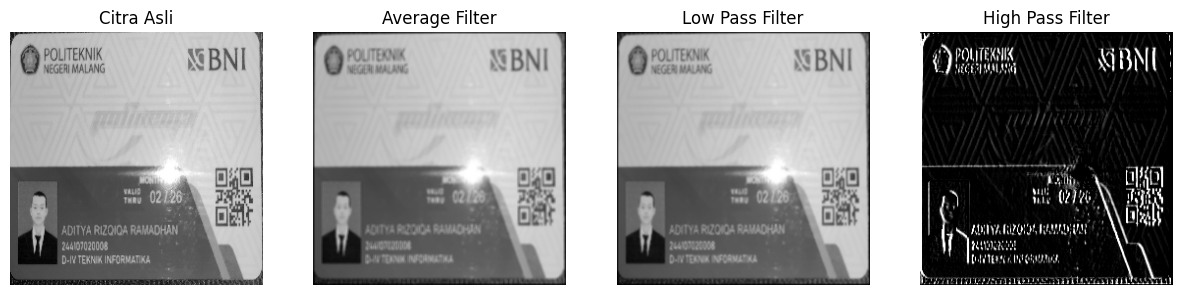

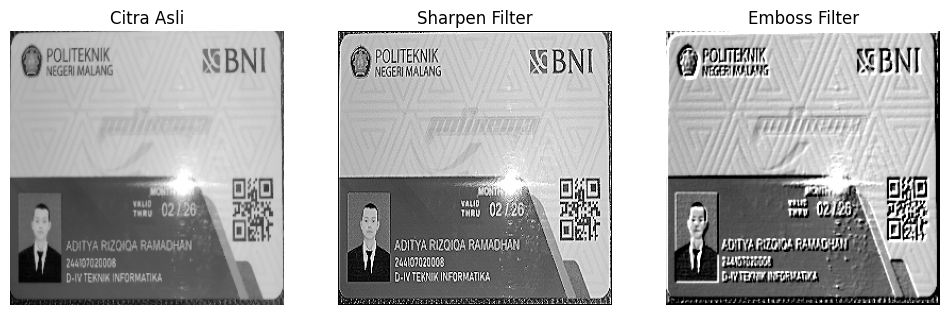

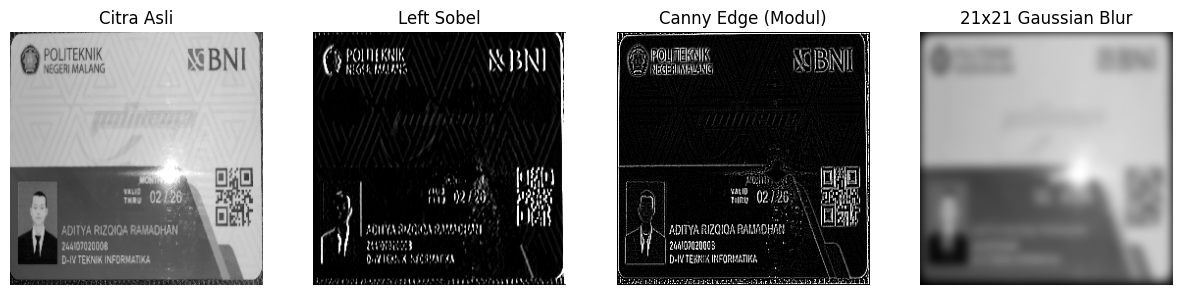

In [31]:
# Eksekusi Filter
# Parameter: (citra, matriks_kernel, stride=1, padding=2)
result_average = convolution2d(img_gray, kernel_average, 1, 2)
result_lpf = convolution2d(img_gray, kernel_lpf, 1, 2)
result_hpf = convolution2d(img_gray, kernel_hpf, 1, 2)

result_sharpen = convolution2d(img_gray, kernel_sharpen, 1, 2)
result_emboss = convolution2d(img_gray, kernel_emboss, 1, 2)

result_left_sobel = convolution2d(img_gray, kernel_left_sobel, 1, 2)
result_canny = convolution2d(img_gray, kernel_canny, 1, 2)

# Menggunakan padding yang disesuaikan dengan ukuran kernel Gaussian (21x21) agar dimensi seimbang
pad_gauss = kernel_size // 2
result_gaussian = convolution2d(img_gray, kernel_gaussian_21, 1, pad_gauss)

# Menampilkan Hasil Kelompok 1 (Basic Filters)
show_side_by_side(
    [img_gray, result_average, result_lpf, result_hpf],
    ["Citra Asli", "Average Filter", "Low Pass Filter", "High Pass Filter"]
)

# Menampilkan Hasil Kelompok 2 (Sharpen & Emboss)
show_side_by_side(
    [img_gray, result_sharpen, result_emboss],
    ["Citra Asli", "Sharpen Filter", "Emboss Filter"],
    figsize=(12, 5)
)

# Menampilkan Hasil Kelompok 3 (Edge Detection & Blur)
show_side_by_side(
    [img_gray, result_left_sobel, result_canny, result_gaussian],
    ["Citra Asli", "Left Sobel", "Canny Edge (Modul)", "21x21 Gaussian Blur"]
)

FILTER LIBRARY DAN FILTER MODERN

1. Percobaan 1 & 2

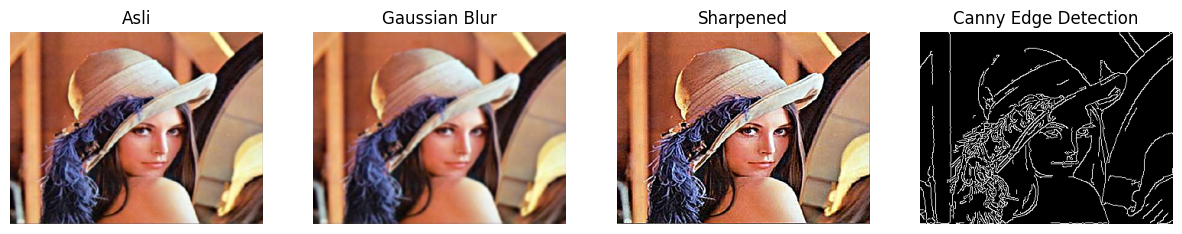

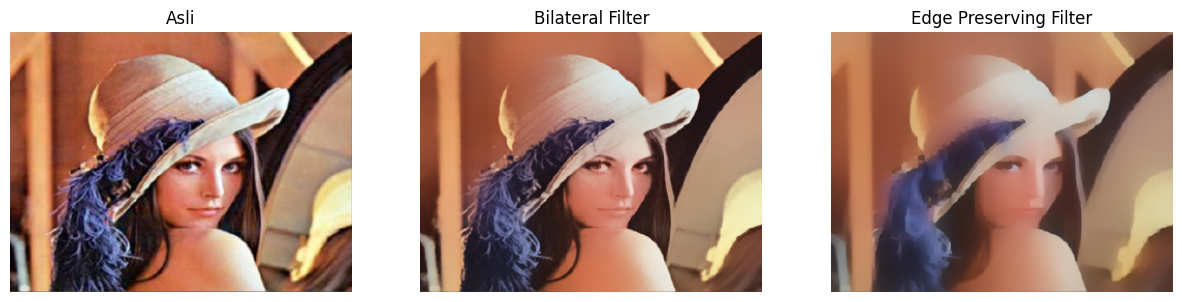

In [32]:
#Fungsi tampil berdampingan
def show_side_by_side(images, titles, figsize=(15,5)):
  plt.figure(figsize=figsize)
  for i, (img, title) in enumerate (zip(images, titles)):
    if len(img.shape) == 2:
      #grayscale
      plt.subplot(1, len(images), i+1)
      plt.imshow(img, cmap="gray")
    else: # color
      plt.subplot(1, len(images), i+1)
      plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
    plt.title(title)
    plt.axis("off")
  plt.show()

img = cv.imread("/content/drive/MyDrive/PCVK/lenna.png")
img_gray = cv.cvtColor(img,cv.COLOR_BGR2GRAY)
blur = cv.GaussianBlur(img, (7,7), 1)
edges = cv.Canny(cv.cvtColor(img, cv.COLOR_BGR2GRAY), 100, 200)

sharpen_kernel = np.array([[0,-1,0], [-1,5,-1], [0,-1,0]])
# Menggunakan -1 untuk ddepth agar format citra output sama dengan citra input
sharpened = cv.filter2D(img, -1, sharpen_kernel)

show_side_by_side([img, blur, sharpened, edges],
["Asli", "Gaussian Blur", "Sharpened", "Canny Edge Detection"])

#Filter Modern dari OpenCV
#Bilateral Filter (edge-preserving)
bilateral = cv.bilateralFilter(img, 50, 100, 100)

#Edge Preserving Filter (alternatif Guided Filter)
edge_preserve = cv.edgePreservingFilter(img, flags=1, sigma_s=100, sigma_r=0.9)

show_side_by_side([img, bilateral, edge_preserve],
["Asli", "Bilateral Filter", "Edge Preserving Filter"])

2. Percobaan 3

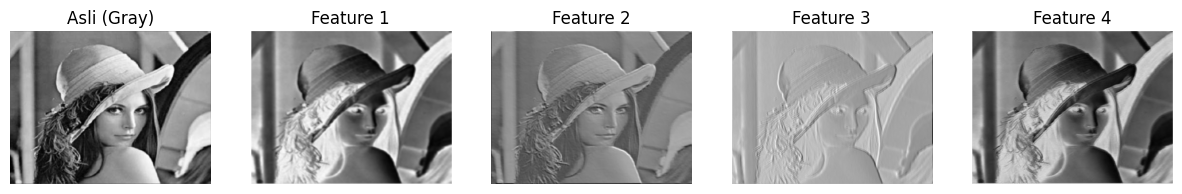

In [33]:
import torch
import torch.nn as nn

class SimpleCNN(nn.Module):
  def __init__(self):
    super(SimpleCNN, self).__init__()
    self.conv1 = nn.Conv2d(1, 4, kernel_size=3, stride=1, padding=1)

  def forward(self, x):
    return self.conv1(x)

model = SimpleCNN()

# Ubah gambar ke tensor
img_tensor = torch.tensor(img_gray, dtype=torch.float32).unsqueeze(0).unsqueeze(0) / 255.0

# Hasil CNN
with torch.no_grad():
  features = model(img_tensor)

# Visualisasi feature maps
feature_maps = [features[0,i].numpy() for i in range(features.shape[1])]
show_side_by_side([img_gray] + feature_maps, ["Asli (Gray)"] + [f"Feature {i+1}" for i in range(len(feature_maps))])

3. Percobaan 4

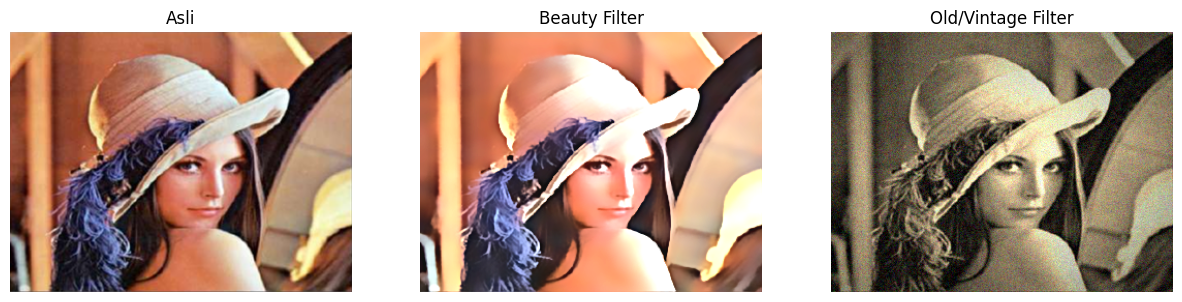

In [34]:
#1. Beauty Filter
#================
#Step 1: Smoothing kulit dengan bilateral filter
smooth = cv.bilateralFilter(img, d=15, sigmaColor=75, sigmaSpace=75)
#Step 2: Unsharp masking (pertajam mata/bibir)
gaussian = cv.GaussianBlur(smooth, (0,0), 3)
sharpened = cv.addWeighted(smooth, 1.5, gaussian, -0.5, 0)
#Step 3: Brightness & contrast
alpha = 1.2 # contrast
beta = 15   # brightness
beauty = cv.convertScaleAbs(sharpened, alpha=alpha, beta=beta)
#================

#2. Old/Vintage Filter
#================
#Step 1: Sepia tone
sepia_kernel = np.array([[0.272, 0.534, 0.131],
                         [0.349, 0.686, 0.168],
                         [0.393, 0.769, 0.189]])
sepia = cv.transform(img, sepia_kernel)
sepia = np.clip(sepia, 0, 255).astype(np.uint8)

#Step 2: Vignette
rows, cols = img.shape[:2]
kernel_x = cv.getGaussianKernel(cols, cols*0.6)
kernel_y = cv.getGaussianKernel(rows, rows*0.6)
kernel = kernel_y * kernel_x.T
mask = kernel / kernel.max()
vignette = np.copy(sepia)
for i in range(3):
    vignette[:,:,i] = vignette[:,:,i] * mask

#Step 3: Noise/Grain
noise = np.random.normal(0, 15, vignette.shape).astype(np.int16)
old_img = np.clip(vignette.astype(np.int16) + noise, 0, 255).astype(np.uint8)

show_side_by_side([img, beauty, old_img], ["Asli", "Beauty Filter", "Old/Vintage Filter"])


4. Percobaan 5

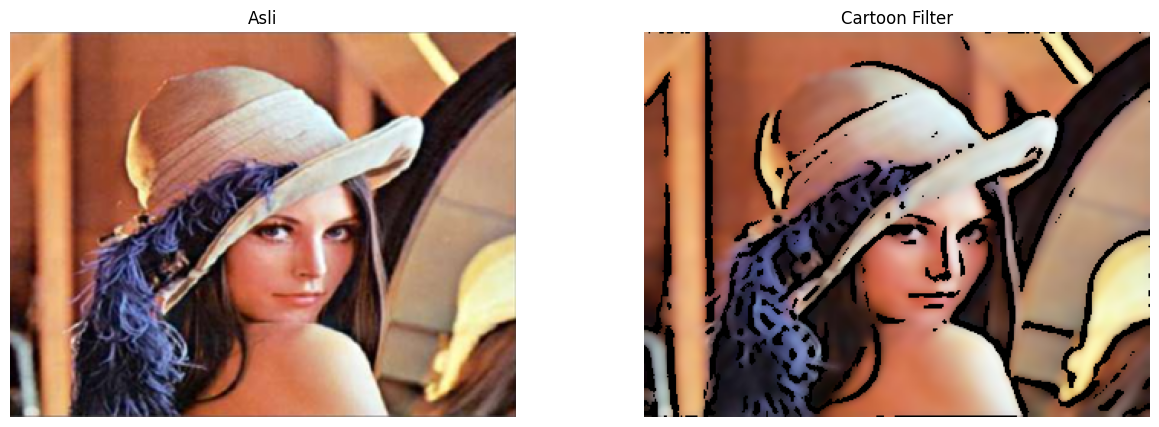

In [35]:
#================
#Step 1: Edge detection
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
gray_blur = cv.medianBlur(gray, 5)
edges = cv.adaptiveThreshold(gray_blur, 255,
                             cv.ADAPTIVE_THRESH_MEAN_C,
                             cv.THRESH_BINARY, 9, 9)

#Step 2: Bilateral Filter untuk smoothing warna
color = cv.bilateralFilter(img, d=9, sigmaColor=200, sigmaSpace=200)

#Step 3: Gabungkan (cartoonize)
cartoon = cv.bitwise_and(color, color, mask=edges)
show_side_by_side([img, cartoon], ["Asli", "Cartoon Filter"])

5. Percobaan 6 & 7


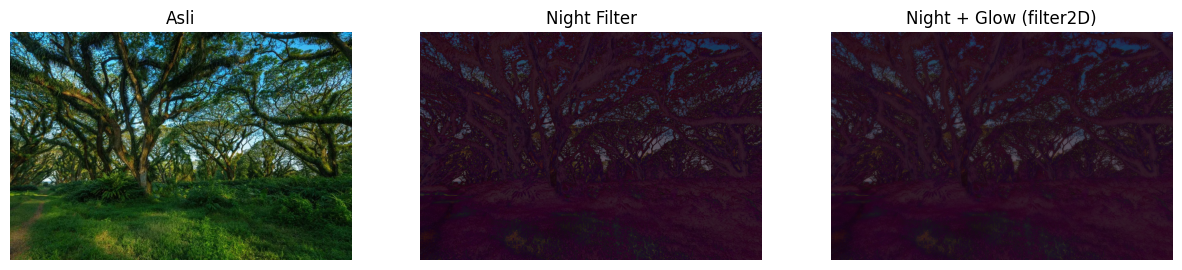

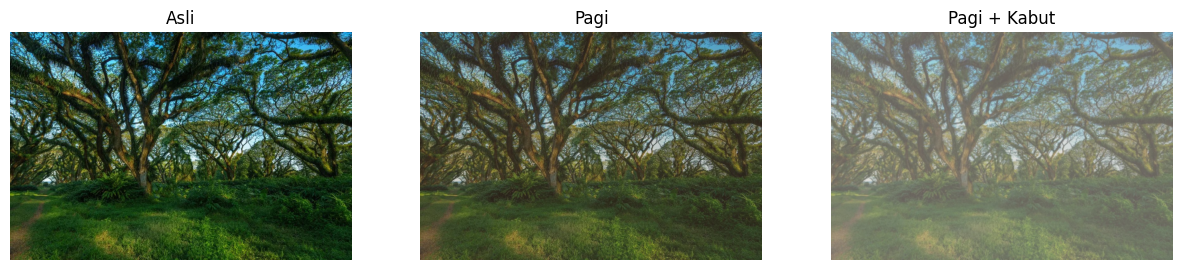

In [36]:
# Filter Malam
img = cv.imread("/content/drive/MyDrive/PCVK/djawatan.jpg")
img_gray = cv.cvtColor(img,cv.COLOR_BGR2GRAY)

#Step 1: Gelapkan (contrast turun, brightness negatif)
night = cv.convertScaleAbs(img, alpha=0.6, beta=-40)

#Step 2: Tambah bias biru
blue_tint = np.full_like(night, (50, 0, 100)) #BGR
night = cv.addWeighted(night, 0.8, blue_tint, 0.2, 0)

#Step 3: Efek glow di area terang dengan filter2D (blur kernel)
kernel = np.ones((15,15), np.float32)/225
glow = cv.filter2D(night, -1, kernel)

#Kombinasikan asli + glow
night_glow = cv.addWeighted(night, 0.7, glow, 0.3, 0)

show_side_by_side([img, night, night_glow],
["Asli", "Night Filter", "Night + Glow (filter2D)"])


# Filter Suasana pagi dan Kabut
# =========================
#Step 1: Kurangi kontras & cerahkan
# =========================
alpha = 0.9 # contrast
beta = 20 # brightness
# =========================
soft = cv.convertScaleAbs(img, alpha=alpha, beta=beta)

# =========================
# Step 2: Tambahkan warm tone (kemerahan / oranye)
# =========================
warm_tint = np.full_like(soft, (40, 70, 120)) # BGR
pagi = cv.addWeighted(soft, 0.8, warm_tint, 0.2, 0)

# =========================
# Step 3: Tambahkan haze (kabut tipis) dengan filter2D
# =========================
kernel = cv.getGaussianKernel(3, 3)
kernel = kernel @ kernel.T # jadikan 2D kernel

kabut = cv.filter2D(pagi, -1, kernel)

white_layer = np.full_like(pagi, 255)
kabut = cv.addWeighted(kabut, 0.7, white_layer, 0.3, 0)

show_side_by_side([img, pagi, kabut],
["Asli", "Pagi", "Pagi + Kabut"])

Tugas Praktikum

TUGAS 1: Analisis Mean vs Median Filter


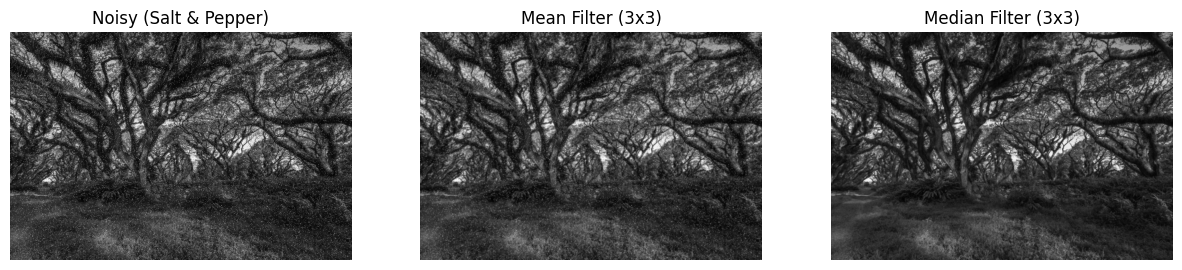


TUGAS 2: Evaluasi Pemilihan Ukuran Kernel Sharpening


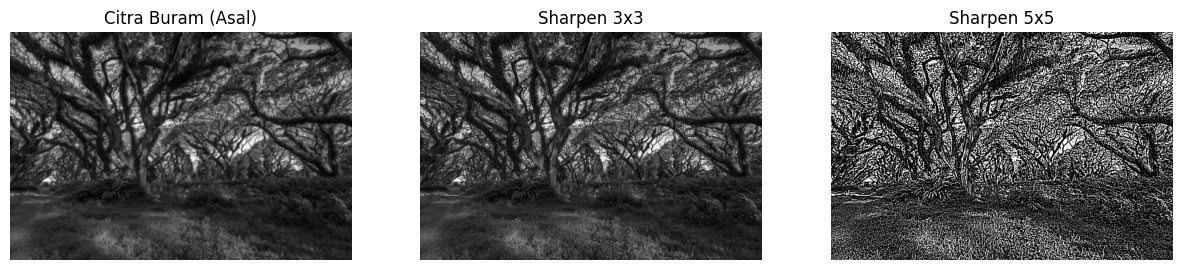


TUGAS 3: Kreasi Filter Kartun Sederhana


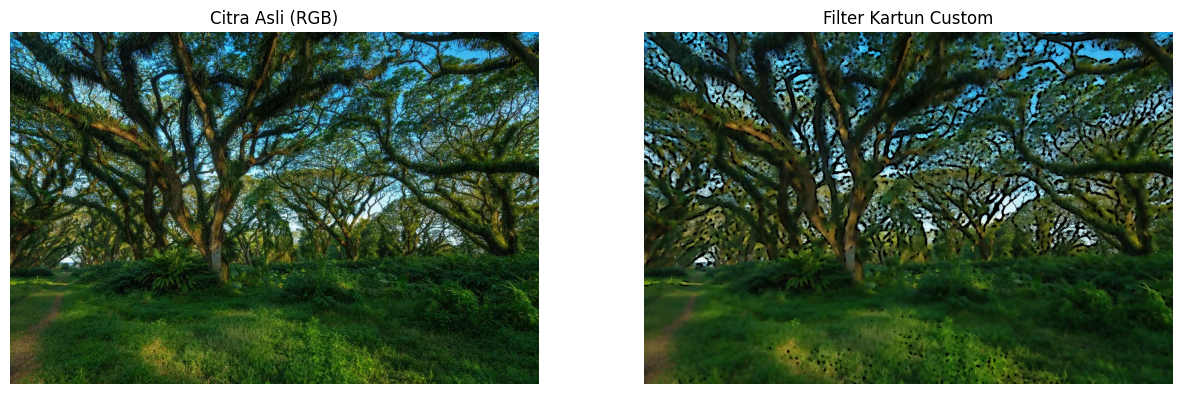

In [37]:
import cv2 as cv
import numpy as np

print("="*50)
print("TUGAS 1: Analisis Mean vs Median Filter")
print("="*50)

# a. Fungsi untuk menambahkan noise Salt and Pepper
def add_salt_and_pepper_noise(image, prob=0.05):
    output = np.copy(image)
    black, white = 0, 255
    # Membuat matriks probabilitas acak
    probs = np.random.random(output.shape)
    # Menerapkan noise hitam (pepper) dan putih (salt)
    output[probs < (prob / 2)] = black
    output[probs > 1 - (prob / 2)] = white
    return output

# Membuat citra bernoise dari citra grayscale
img_noisy = add_salt_and_pepper_noise(img_gray, prob=0.05)

# b. Menerapkan Mean Filter (3x3) dan Median Filter (3x3)
mean_filtered = cv.blur(img_noisy, (3, 3))
median_filtered = cv.medianBlur(img_noisy, 3)

show_side_by_side(
    [img_noisy, mean_filtered, median_filtered],
    ["Noisy (Salt & Pepper)", "Mean Filter (3x3)", "Median Filter (3x3)"]
)

print("\n" + "="*50)
print("TUGAS 2: Evaluasi Pemilihan Ukuran Kernel Sharpening")
print("="*50)

# Membuat gambar sedikit buram (blurry) sebagai base
img_blurry = cv.GaussianBlur(img_gray, (5, 5), 0)

# a. Buat kernel penajaman ukuran 3x3 dan 5x5
kernel_sharpen_3x3 = np.array([[ 0, -1,  0],
                               [-1,  5, -1],
                               [ 0, -1,  0]])

# Kernel 5x5 (Pendekatan Unsharp Masking)
kernel_sharpen_5x5 = np.array([[-1, -1, -1, -1, -1],
                               [-1, -1, -1, -1, -1],
                               [-1, -1, 25, -1, -1],
                               [-1, -1, -1, -1, -1],
                               [-1, -1, -1, -1, -1]])

# b. Menerapkan pada citra buram
sharpen_3x3 = cv.filter2D(img_blurry, -1, kernel_sharpen_3x3)
sharpen_5x5 = cv.filter2D(img_blurry, -1, kernel_sharpen_5x5)

show_side_by_side(
    [img_blurry, sharpen_3x3, sharpen_5x5],
    ["Citra Buram (Asal)", "Sharpen 3x3", "Sharpen 5x5"]
)


print("\n" + "="*50)
print("TUGAS 3: Kreasi Filter Kartun Sederhana")
print("="*50)

def kartun(image):
    color = cv.bilateralFilter(image, d=9, sigmaColor=75, sigmaSpace=75)
    gray = cv.cvtColor(image, cv.COLOR_BGR2GRAY)
    gray_blur = cv.medianBlur(gray, 7)
    edges = cv.adaptiveThreshold(gray_blur, 255,
                                 cv.ADAPTIVE_THRESH_MEAN_C,
                                 cv.THRESH_BINARY, 9, 9)

    cartoon = cv.bitwise_and(color, color, mask=edges)
    return cartoon

img_cartoon = kartun(img)
show_side_by_side([img, img_cartoon], ["Citra Asli (RGB)", "Filter Kartun Custom"])